# Data Cleaning: State Health Spending and NFHS-5 Outcomes

In [31]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

from outliers import smirnov_grubbs as grubbs
from pyampute.exploration.mcar_statistical_tests import MCARTest

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.decomposition import PCA
from sklearn.cluster import DBSCAN
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [32]:
RAW_PATH = "data/interim/budget_nfhs_combined.csv"
raw = pd.read_csv(RAW_PATH, header=None)
print("Raw shape:", raw.shape)
raw.iloc[:5, :10]


Raw shape: (31, 182)


,0,1,2,3,4,5,6,7,8,9
0,State,Population (Total),Accounts,Budget Estimates,Revised Estimates,Population below age 15 years (%),NaN,NaN,Sex ratio of the total population (females per...,NaN
1,NaN,NaN,NaN,NaN,NaN,Urban,Rural,Total,Urban,Rural
2,Andhra Pradesh,"5,25,04,000","5,25,929.60",605549.45,526323.02,21.3,22.6,22.2,1024,1055
3,Arunachal Pradesh,"15,19,000",92615,131266.59,91612.2,26.2,27.2,27.1,989,998
4,Assam,"3,46,68,000",451977.3,591193.62,633180.84,21.3,29.5,28.3,982,1017


## DATA INSPECTION

In [33]:
empty_cols = [c for c in raw.columns if raw.iloc[2:, c].isna().all()]
print(f"{len(empty_cols)} fully empty columns found, out of {raw.shape[1]} total.")
raw.iloc[:3, empty_cols[:3]]


18 fully empty columns found, out of 182 total.


,164,165,166
0,NaN,NaN,NaN
1,NaN,NaN,NaN
2,NaN,NaN,NaN


In [34]:
# reshaping the two row header
non_empty_cols = [c for c in raw.columns if c not in empty_cols]
row0 = raw.iloc[0, non_empty_cols].ffill()
row1 = raw.iloc[1, non_empty_cols]

new_cols = []
for top, sub in zip(row0, row1):
    top = str(top).strip()
    if pd.isna(sub):
        new_cols.append(top)
    else:
        new_cols.append(f"{top} ({str(sub).strip()})")

print("Duplicate column names after reshaping:", pd.Series(new_cols).duplicated().sum())

df_raw = raw.iloc[2:, non_empty_cols].copy()
df_raw.columns = new_cols
df_raw = df_raw.reset_index(drop=True)

print("Reshaped shape:", df_raw.shape)
df_raw.head()


Duplicate column names after reshaping: 0
Reshaped shape: (29, 164)


,State,Population (Total),Accounts,Budget Estimates,Revised Estimates,Population below age 15 years (%) (Urban),Population below age 15 years (%) (Rural),Population below age 15 years (%) (Total),"Sex ratio of the total population (females per 1,000 males) (Urban)","Sex ratio of the total population (females per 1,000 males) (Rural)",...,All women age 15-49 years who are anaemic (%) (Total),Women whose Body Mass Index (BMI) is below normal (BMI <18.5 kg/m2) (%) (Urban),Women whose Body Mass Index (BMI) is below normal (BMI <18.5 kg/m2) (%) (Rural),Women whose Body Mass Index (BMI) is below normal (BMI <18.5 kg/m2) (%) (Total),Women who are literate (%) (Urban),Women who are literate (%) (Rural),Women who are literate (%) (Total),Women with 10 or more years of schooling (%) (Urban),Women with 10 or more years of schooling (%) (Rural),Women with 10 or more years of schooling (%) (Total)
0,Andhra Pradesh,"5,25,04,000","5,25,929.60",605549.45,526323.02,21.3,22.6,22.2,1024,1055,...,58.8,11.9,16.2,14.8,79,63.8,68.6,51.2,34.3,39.6
1,Arunachal Pradesh,"15,19,000",92615,131266.59,91612.2,26.2,27.2,27.1,989,998,...,40.3,5.6,5.7,5.7,82.9,69,71.3,55.4,36.2,39.4
2,Assam,"3,46,68,000",451977.3,591193.62,633180.84,21.3,29.5,28.3,982,1017,...,65.9,13.9,18.3,17.6,87.5,75.4,77.2,49,26.2,29.6
3,Bihar,"12,13,02,000",611797.7,"6,38,425.20","7,24,500.80",31.6,37.2,36.4,982,1111,...,63.5,18.7,26.9,25.6,74.9,54.5,57.8,48,25.2,28.8
4,Chhattisgarh,"2,91,09,000",404904.7,"4,03,411.10","4,42,702.30",23.2,26,25.4,1016,1014,...,60.8,16,25.3,23.1,83.4,69.1,72.5,52.4,32.1,36.9


In [35]:
df_raw.info()


<class 'pandas.DataFrame'>
RangeIndex: 29 entries, 0 to 28
Columns: 164 entries, State to Women with 10 or more years of schooling (%) (Total)
dtypes: str(164)
memory usage: 37.3 KB


### Fixing data types

Since the four budget and population columns use commas (Indian numbering system, eg: 6,76,767) which make the it object dtype instead of float. 

In [36]:
df = df_raw.copy()

money_cols = ["Population (Total)", "Accounts", "Budget Estimates", "Revised Estimates"]
for c in money_cols:
    df[c] = (
        df[c].astype(str).str.replace(",", "", regex=False).str.strip().astype(float)
    )

df["State"] = df["State"].str.strip()

other_cols = [c for c in df.columns if c not in ["State"] + money_cols]
df[other_cols] = df[other_cols].apply(pd.to_numeric, errors="coerce")

print(df.dtypes.value_counts())
df[money_cols].describe()


float64    151
int64       12
str          1
Name: count, dtype: int64


,Population (Total),Accounts,Budget Estimates,Revised Estimates
count,2.900000e+01,2.900000e+01,2.900000e+01,2.900000e+01
mean,4.560066e+07,4.506780e+05,4.805445e+05,4.812330e+05
std,5.072978e+07,3.472663e+05,3.685084e+05,3.691624e+05
min,6.700000e+05,3.604670e+04,3.587860e+04,3.949860e+04
25%,4.032000e+06,9.298630e+04,1.312666e+05,1.060341e+05
50%,3.466800e+07,4.049047e+05,4.034111e+05,4.427023e+05
75%,6.886200e+07,6.742422e+05,6.912670e+05,7.245008e+05
max,2.279430e+08,1.245497e+06,1.363618e+06,1.370988e+06


#### Correcting the state name spellings to be consistent across every data files

In [37]:
state_name_corrections = {
    "Chattisgarh": "Chhatisgarh",
    "Uttarkhand": "Uttarakhand",
}

before = df["State"].tolist()
df["State"] = df["State"].replace(state_name_corrections)
after = df["State"].tolist()

## Feature engineering: per capita health expenditure

Accounts, Budget Estimates and Revised Estimates are absolute figures in Rs. lakh, so a
large state will always out-spend a small one even if it spends less per person. To avoid this bias, we invent a new feature to normalize it across different states

In [38]:
df["Per_Capita_Health_Exp_Accounts"] = df["Accounts"]          * 1e5 / df["Population (Total)"]
df["Per_Capita_Health_Exp_BE"]       = df["Budget Estimates"]  * 1e5 / df["Population (Total)"]
df["Per_Capita_Health_Exp_RE"]       = df["Revised Estimates"] * 1e5 / df["Population (Total)"]

exp_cols = ["Per_Capita_Health_Exp_Accounts", "Per_Capita_Health_Exp_BE", "Per_Capita_Health_Exp_RE"]
df[["State"] + exp_cols].sort_values("Per_Capita_Health_Exp_Accounts", ascending=False)


,State,Per_Capita_Health_Exp_Accounts,Per_Capita_Health_Exp_BE,Per_Capita_Health_Exp_RE
1,Arunachal Pradesh,6097.103357,8641.645161,6031.086241
5,Goa,6002.989025,6853.783086,6845.326017
22,Sikkim,5380.104478,5355.014925,5895.313433
17,Mizoram,4220.332226,4286.951827,4812.732558
18,Nagaland,2875.697835,3176.144634,3177.535698
9,Jammu and Kashmir,2646.332206,2712.886885,3112.501315
16,Meghalaya,2321.738329,3068.931204,3068.931204
8,Himachal Pradesh,2261.528515,2668.029128,2656.041922
15,Manipur,1915.603063,2227.054882,2294.262923
12,Kerala,1909.655876,1808.166086,1838.365480


## Visual data inspection

We use the Total columns for the headline variables, since that is the state level figure
comparable to earlier rounds. A correlation heatmap and a missingness bar give
a first look at structure.

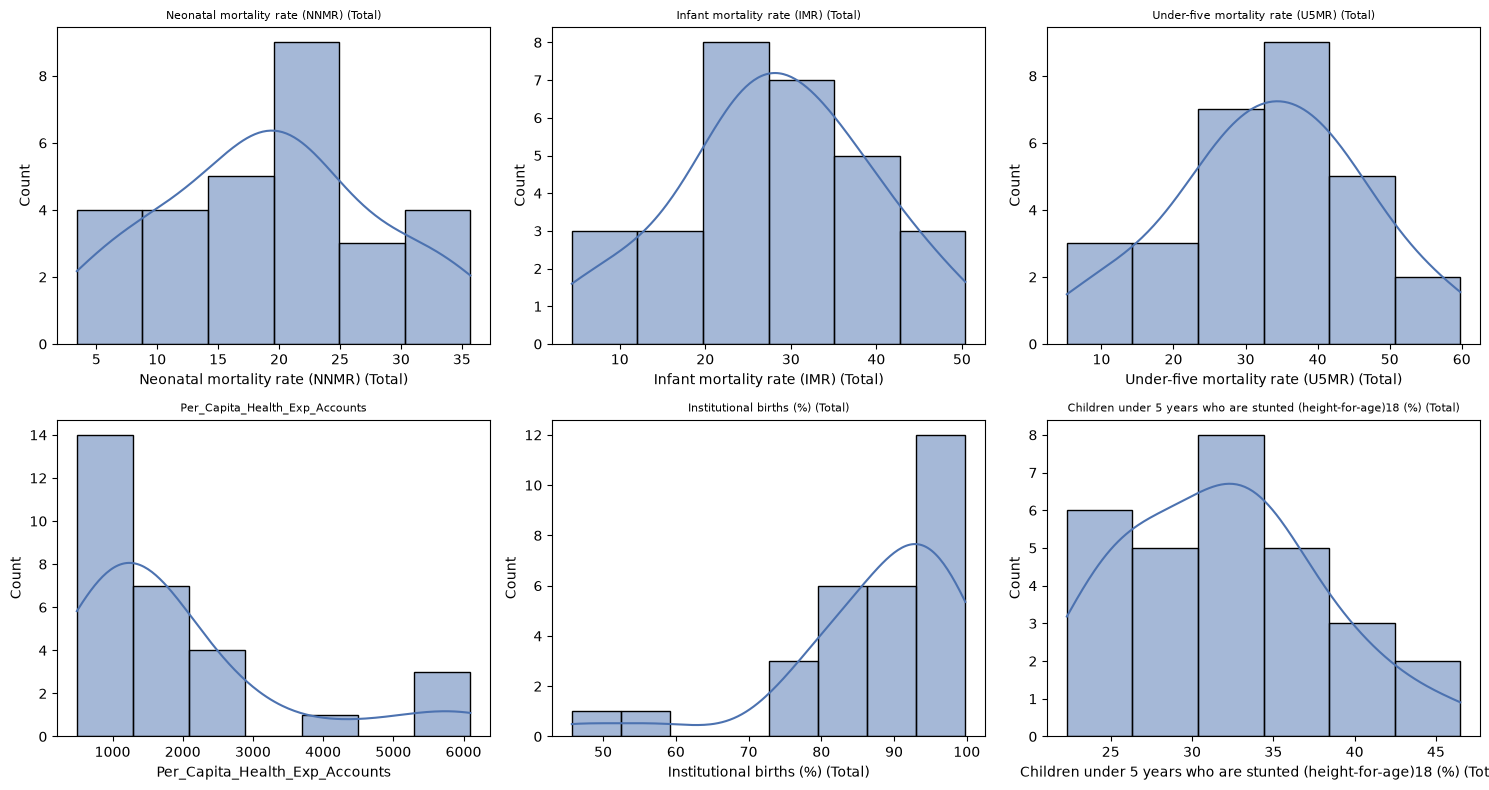

In [39]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()

key_vars = [
    "Neonatal mortality rate (NNMR) (Total)",
    "Infant mortality rate (IMR) (Total)",
    "Under-five mortality rate (U5MR) (Total)",
    "Per_Capita_Health_Exp_Accounts",
    "Institutional births (%) (Total)",
    "Children under 5 years who are stunted (height-for-age)18 (%) (Total)",
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, key_vars):
    sns.histplot(df[col].dropna(), kde=True, ax=ax, color="#4C72B0")
    ax.set_title(col, fontsize=8)
plt.tight_layout()
plt.show()


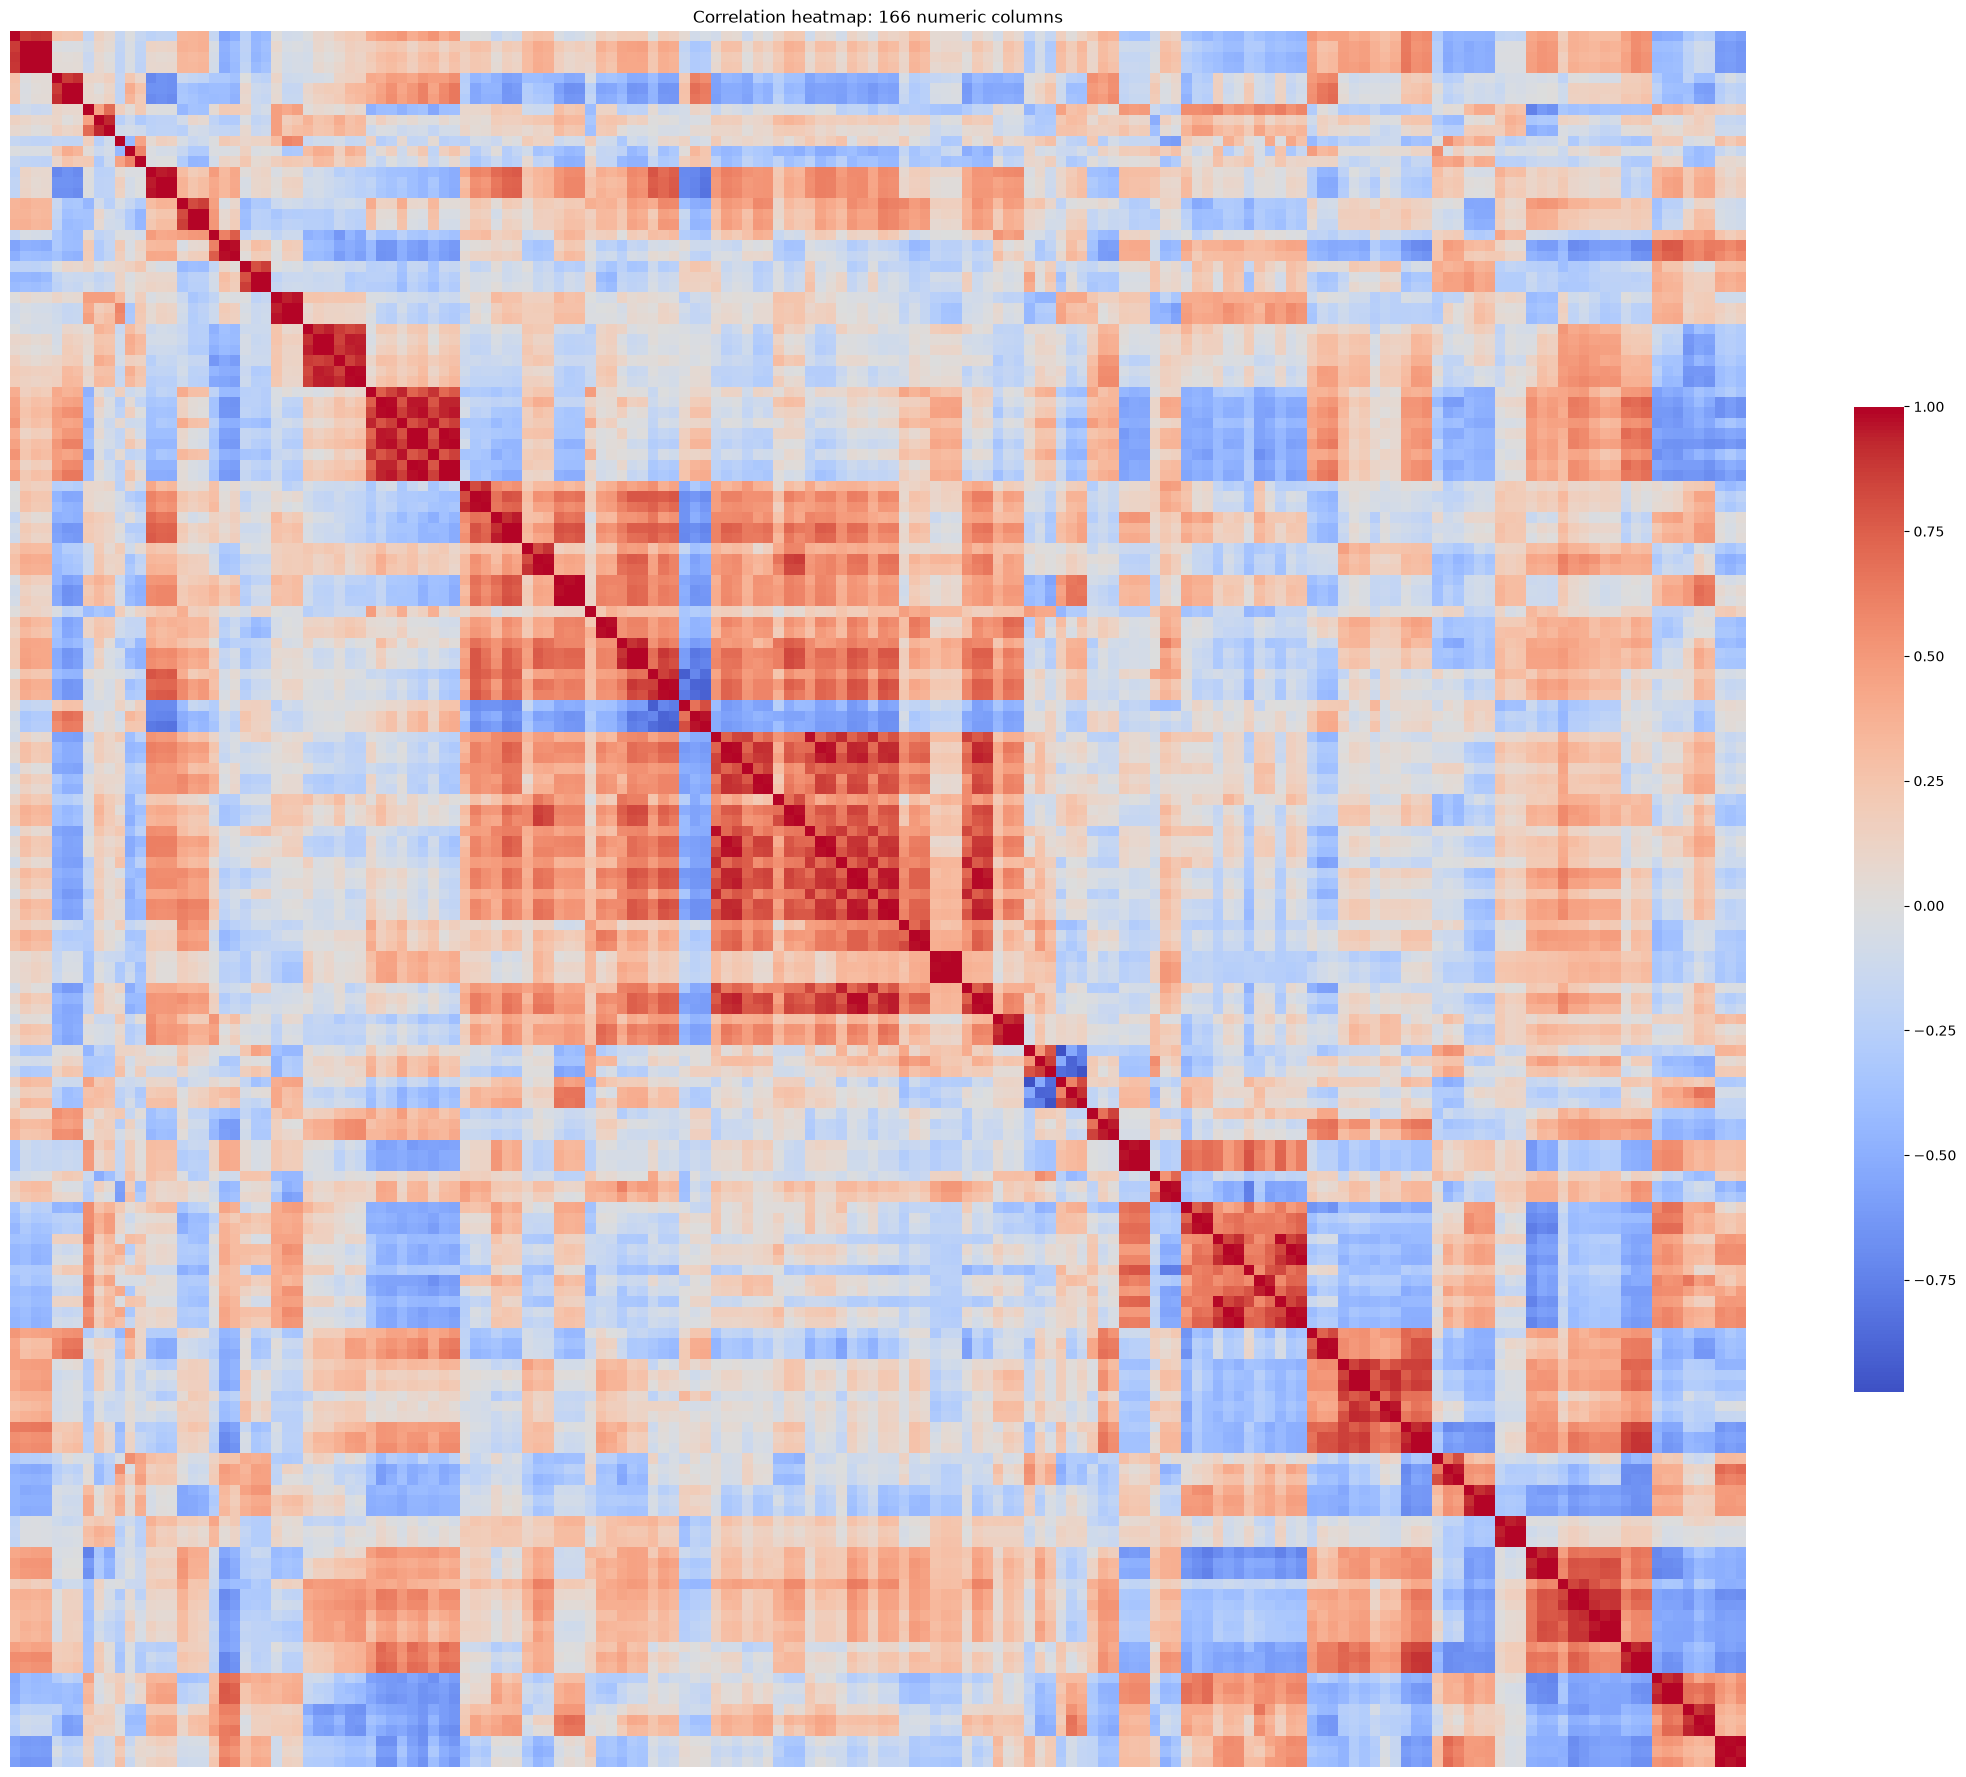

In [40]:
fig, ax = plt.subplots(figsize=(22, 20))
corr = df[numeric_cols].corr()
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, ax=ax,
            cbar_kws={"shrink": 0.5}, xticklabels=False, yticklabels=False)
ax.set_title(f"Correlation heatmap: {len(numeric_cols)} numeric columns")
plt.tight_layout()
plt.show()


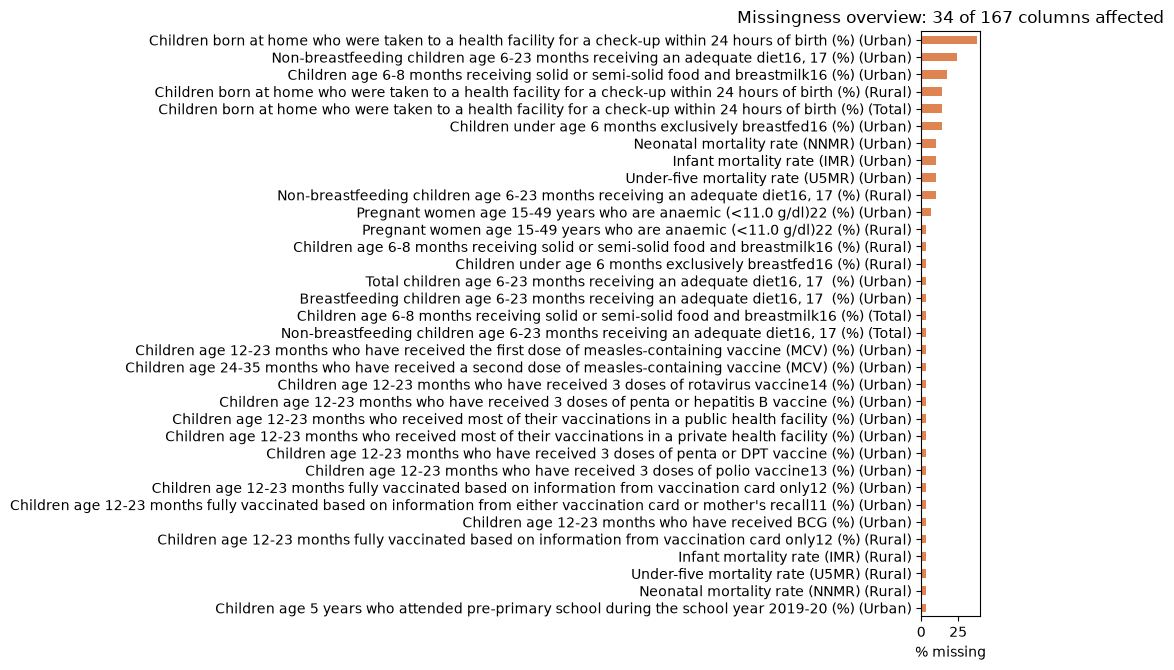

In [41]:
na_counts_preview = df.isna().sum()
na_pct_preview = (na_counts_preview / len(df) * 100).round(1)
preview = pd.DataFrame({"n_missing": na_counts_preview, "pct_missing": na_pct_preview}).query("n_missing > 0")

fig, ax = plt.subplots(figsize=(10, max(4, 0.2 * len(preview))))
preview["pct_missing"].sort_values().plot.barh(ax=ax, color="#DD8452")
ax.set_xlabel("% missing")
ax.set_title(f"Missingness overview: {len(preview)} of {df.shape[1]} columns affected")
plt.tight_layout()
plt.show()


## Duplicate check

In [42]:
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicate state names:", df['State'].duplicated().sum())
print("Row count vs expected state count:", len(df), "rows for", df['State'].nunique(), "unique states")


Fully duplicated rows: 0
Duplicate state names: 0
Row count vs expected state count: 29 rows for 29 unique states


No duplicate rows and no duplicate state names. No action needed.

## Outlier detection

Five methods are used to test outliers : IQR, modified Z-score and Grubbs' test which look at one column at a
time, while DBSCAN and Local Outlier Factor look at all columns together. To make it more robust, an outlier is marked only if at least two methods agree. 

### IQR method

In [43]:
def iqr_outlier_report(data, cols):
    rows = []
    for c in cols:
        s = data[c].dropna()
        if s.empty:
            continue
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        mask = (s < lo) | (s > hi)
        if mask.sum() > 0:
            rows.append({
                "column": c,
                "n_outliers": int(mask.sum()),
                "lower_bound": round(lo, 2),
                "upper_bound": round(hi, 2),
                "outlier_states": data.loc[s[mask].index, "State"].tolist(),
            })
    return pd.DataFrame(rows).sort_values("n_outliers", ascending=False)

iqr_report = iqr_outlier_report(df, numeric_cols)
iqr_report


,column,n_outliers,lower_bound,upper_bound,outlier_states
70,Children under 5 years who are overweight (wei...,5,0.90,7.30,"[Arunachal Pradesh, Jammu and Kashmir, Mizoram..."
69,Children under 5 years who are overweight (wei...,5,1.00,6.60,"[Arunachal Pradesh, Jammu and Kashmir, Mizoram..."
27,Mothers whose last birth was protected against...,4,84.00,98.40,"[Arunachal Pradesh, Meghalaya, Mizoram, Nagaland]"
28,Mothers whose last birth was protected against...,4,83.60,99.60,"[Arunachal Pradesh, Meghalaya, Mizoram, Nagaland]"
44,Children age 12-23 months who have received BC...,4,89.60,100.80,"[Arunachal Pradesh, Meghalaya, Mizoram, Nagaland]"
...,...,...,...,...,...
74,Pregnant women age 15-49 years who are anaemic...,1,25.79,74.49,[Nagaland]
77,Women with 10 or more years of schooling (%) (...,1,2.10,69.30,[Kerala]
76,Women with 10 or more years of schooling (%) (...,1,34.55,78.95,[Himachal Pradesh]
75,Pregnant women age 15-49 years who are anaemic...,1,24.20,72.20,[Nagaland]


### Modified Z-score (MAD based)

In [44]:
def modified_zscore_outlier_report(data, cols, threshold=3.5):
    rows = []
    for c in cols:
        s = data[c].dropna()
        if s.empty:
            continue
        median = s.median()
        mad = (s - median).abs().median()
        if mad == 0:
            continue
        mod_z = 0.6745 * (s - median) / mad
        mask = mod_z.abs() > threshold
        if mask.sum() > 0:
            rows.append({
                "column": c,
                "n_outliers": int(mask.sum()),
                "outlier_states": data.loc[s[mask].index, "State"].tolist(),
            })
    return pd.DataFrame(rows).sort_values("n_outliers", ascending=False)

modz_report = modified_zscore_outlier_report(df, numeric_cols)
modz_report


,column,n_outliers,outlier_states
45,Children under 5 years who are overweight (wei...,5,"[Arunachal Pradesh, Jammu and Kashmir, Mizoram..."
46,Children under 5 years who are overweight (wei...,5,"[Arunachal Pradesh, Jammu and Kashmir, Mizoram..."
31,Children age 12-23 months who have received BC...,4,"[Arunachal Pradesh, Meghalaya, Mizoram, Nagaland]"
50,Per_Capita_Health_Exp_Accounts,4,"[Arunachal Pradesh, Goa, Mizoram, Sikkim]"
51,Per_Capita_Health_Exp_BE,4,"[Arunachal Pradesh, Goa, Mizoram, Sikkim]"
52,Per_Capita_Health_Exp_RE,4,"[Arunachal Pradesh, Goa, Mizoram, Sikkim]"
32,Children age 12-23 months who have received BC...,3,"[Arunachal Pradesh, Mizoram, Nagaland]"
21,Children born at home who were taken to a heal...,3,"[Andhra Pradesh, Karnataka, Telangana]"
6,Children under age 5 years whose birth was reg...,3,"[Bihar, Jharkhand, Nagaland]"
19,Mothers whose last birth was protected against...,3,"[Arunachal Pradesh, Mizoram, Nagaland]"


### Grubbs' test

A formal hypothesis test for whether the single most extreme value in a column is an outlier,
given its sample size. Useful cross check at small n, where IQR or MAD bounds can be unstable.

In [45]:
def grubbs_outlier_report(data, cols, alpha=0.05):
    rows = []
    for c in cols:
        s = data[c].dropna()
        if len(s) < 7:
            continue
        try:
            outlier_idx = grubbs.two_sided_test_indices(s.values, alpha=alpha)
        except Exception:
            continue
        if len(outlier_idx) > 0:
            flagged_index = s.index[outlier_idx]
            rows.append({
                "column": c,
                "n_outliers": len(outlier_idx),
                "outlier_states": data.loc[flagged_index, "State"].tolist(),
                "outlier_values": s.iloc[outlier_idx].round(2).tolist(),
            })
    return pd.DataFrame(rows).sort_values("n_outliers", ascending=False)

grubbs_report = grubbs_outlier_report(df, numeric_cols)
grubbs_report


,column,n_outliers,outlier_states,outlier_values
36,Per_Capita_Health_Exp_BE,4,"[Arunachal Pradesh, Goa, Sikkim, Mizoram]","[8641.65, 6853.78, 5355.01, 4286.95]"
21,Children age 12-23 months who have received BC...,4,"[Mizoram, Nagaland, Arunachal Pradesh, Meghalaya]","[83.4, 85.5, 87.9, 89.3]"
6,Population living in households with an improv...,2,"[Manipur, Meghalaya]","[68.9, 75.6]"
7,Population living in households with an improv...,2,"[Manipur, Meghalaya]","[77.1, 79.2]"
16,Institutional births (%) (Rural),2,"[Nagaland, Meghalaya]","[38.8, 54.3]"
34,Average out-of-pocket expenditure per delivery...,2,"[Manipur, Arunachal Pradesh]","[13564, 9649]"
17,Institutional births (%) (Total),2,"[Nagaland, Meghalaya]","[45.7, 58.1]"
12,Women age 15-19 years who were already mothers...,2,"[Tripura, West Bengal]","[24.3, 19.6]"
13,Women age 15-19 years who were already mothers...,2,"[Tripura, West Bengal]","[21.9, 16.4]"
0,Population (Total),1,[Uttar Pradesh],[227943000.0]


### DBSCAN (multivariate)

Reduced 166 columns to 14 principal components (90% variance retained).


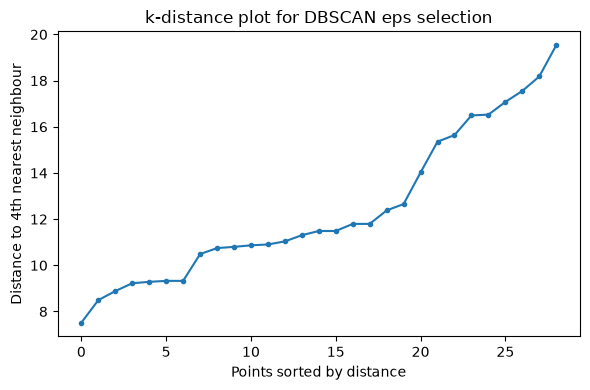

In [46]:
X_for_outliers = pd.DataFrame(
    SimpleImputer(strategy="mean").fit_transform(df[numeric_cols]),
    columns=numeric_cols, index=df.index,
)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_for_outliers)

pca_outliers = PCA(n_components=0.90, random_state=RANDOM_STATE)
X_pca = pca_outliers.fit_transform(X_scaled)
print(f"Reduced {X_scaled.shape[1]} columns to {X_pca.shape[1]} principal components "
      f"(90% variance retained).")

k_dist = np.sort(NearestNeighbors(n_neighbors=4).fit(X_pca).kneighbors(X_pca)[0][:, -1])
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(k_dist, marker="o", markersize=3)
ax.set_xlabel("Points sorted by distance")
ax.set_ylabel("Distance to 4th nearest neighbour")
ax.set_title("k-distance plot for DBSCAN eps selection")
plt.tight_layout()
plt.show()


In [47]:
dbscan = DBSCAN(eps=12.0, min_samples=3)
db_labels = dbscan.fit_predict(X_pca)

dbscan_flagged = df.loc[db_labels == -1, ["State"]].copy()
dbscan_flagged["dbscan_label"] = "noise / outlier"
print(f"DBSCAN flagged {len(dbscan_flagged)} of {len(df)} states as noise "
      f"(eps=12.0 from the elbow above, min_samples=3, on PCA-reduced space).")
dbscan_flagged


DBSCAN flagged 6 of 29 states as noise (eps=12.0 from the elbow above, min_samples=3, on PCA-reduced space).


,State,dbscan_label
1,Arunachal Pradesh,noise / outlier
15,Manipur,noise / outlier
16,Meghalaya,noise / outlier
17,Mizoram,noise / outlier
18,Nagaland,noise / outlier
22,Sikkim,noise / outlier


### Local Outlier Factor

In [48]:
lof = LocalOutlierFactor(n_neighbors=3)
lof_labels = lof.fit_predict(X_pca)
lof_scores = -lof.negative_outlier_factor_

lof_flagged = df.loc[lof_labels == -1, ["State"]].copy()
lof_flagged["lof_score"] = lof_scores[lof_labels == -1].round(2)
print(f"LOF flagged {len(lof_flagged)} of {len(df)} states (n_neighbors=3, PCA-reduced space).")
lof_flagged.sort_values("lof_score", ascending=False)


LOF flagged 0 of 29 states (n_neighbors=3, PCA-reduced space).


,State,lof_score


### Cross method agreement

In [49]:
multivariate_flags = set(dbscan_flagged["State"]) | set(lof_flagged["State"])
both_multivariate = set(dbscan_flagged["State"]) & set(lof_flagged["State"])

print("States flagged by DBSCAN:", sorted(dbscan_flagged["State"]))
print("States flagged by LOF:   ", sorted(lof_flagged["State"]))
print("States flagged by BOTH multivariate methods:", sorted(both_multivariate))

univariate_states = set()
for rep in [iqr_report, modz_report, grubbs_report]:
    for lst in rep.get("outlier_states", []):
        univariate_states.update(lst)

corroborated = multivariate_flags & univariate_states
print("\nMultivariate-flagged states that ALSO show up in at least one univariate flag:", sorted(corroborated))


States flagged by DBSCAN: ['Arunachal Pradesh', 'Manipur', 'Meghalaya', 'Mizoram', 'Nagaland', 'Sikkim']
States flagged by LOF:    []
States flagged by BOTH multivariate methods: []

Multivariate-flagged states that ALSO show up in at least one univariate flag: ['Arunachal Pradesh', 'Manipur', 'Meghalaya', 'Mizoram', 'Nagaland', 'Sikkim']


### Decision

We are not flagging any data point as outlier.
Reasons :
- The flagged states are mostly small hill and north eastern states, genuinely different in
scale and survey logistics from the larger plains states
- Every flagged value is a plausible, in range figure. 
- Also since this is the data released by the govt organization, there is more chance that this is double checked and carefully entried

## Missing value analysis

### Counts and percentages

In [50]:
na_counts = df.isna().sum()
na_pct = (na_counts / len(df) * 100).round(1)

missing_summary = (
    pd.DataFrame({"n_missing": na_counts, "pct_missing": na_pct})
    .query("n_missing > 0")
    .sort_values("n_missing", ascending=False)
)
missing_cols = missing_summary.index.tolist()
print(f"{len(missing_cols)} of {df.shape[1]} columns have at least one missing value "
      f"(out of {len(df)} rows).")
missing_summary.head(20)


34 of 167 columns have at least one missing value (out of 29 rows).


,n_missing,pct_missing
Children born at home who were taken to a health facility for a check-up within 24 hours of birth (%) (Urban),11,37.9
"Non-breastfeeding children age 6-23 months receiving an adequate diet16, 17 (%) (Urban)",7,24.1
Children age 6-8 months receiving solid or semi-solid food and breastmilk16 (%) (Urban),5,17.2
Children under age 6 months exclusively breastfed16 (%) (Urban),4,13.8
Children born at home who were taken to a health facility for a check-up within 24 hours of birth (%) (Total),4,13.8
Children born at home who were taken to a health facility for a check-up within 24 hours of birth (%) (Rural),4,13.8
"Non-breastfeeding children age 6-23 months receiving an adequate diet16, 17 (%) (Rural)",3,10.3
Neonatal mortality rate (NNMR) (Urban),3,10.3
Under-five mortality rate (U5MR) (Urban),3,10.3
Infant mortality rate (IMR) (Urban),3,10.3


### Missingness pattern across states

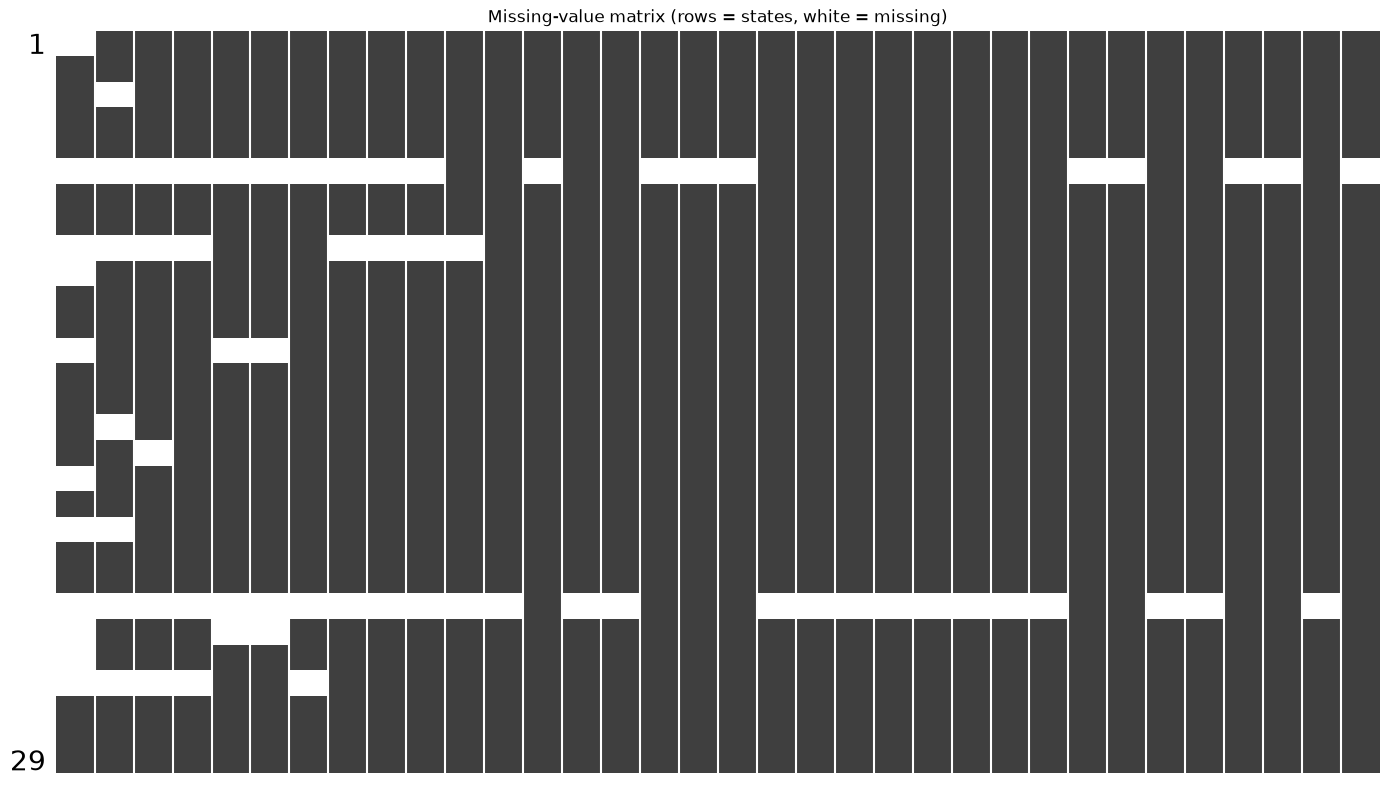

In [51]:
fig, ax = plt.subplots(figsize=(14, 8))
msno.matrix(df[missing_cols], ax=ax, sparkline=False, labels=False)
ax.set_title("Missing-value matrix (rows = states, white = missing)")
plt.tight_layout()
plt.show()


### Co-missingness structure

If several columns go missing together, that points to a shared cause rather than independent
failures.

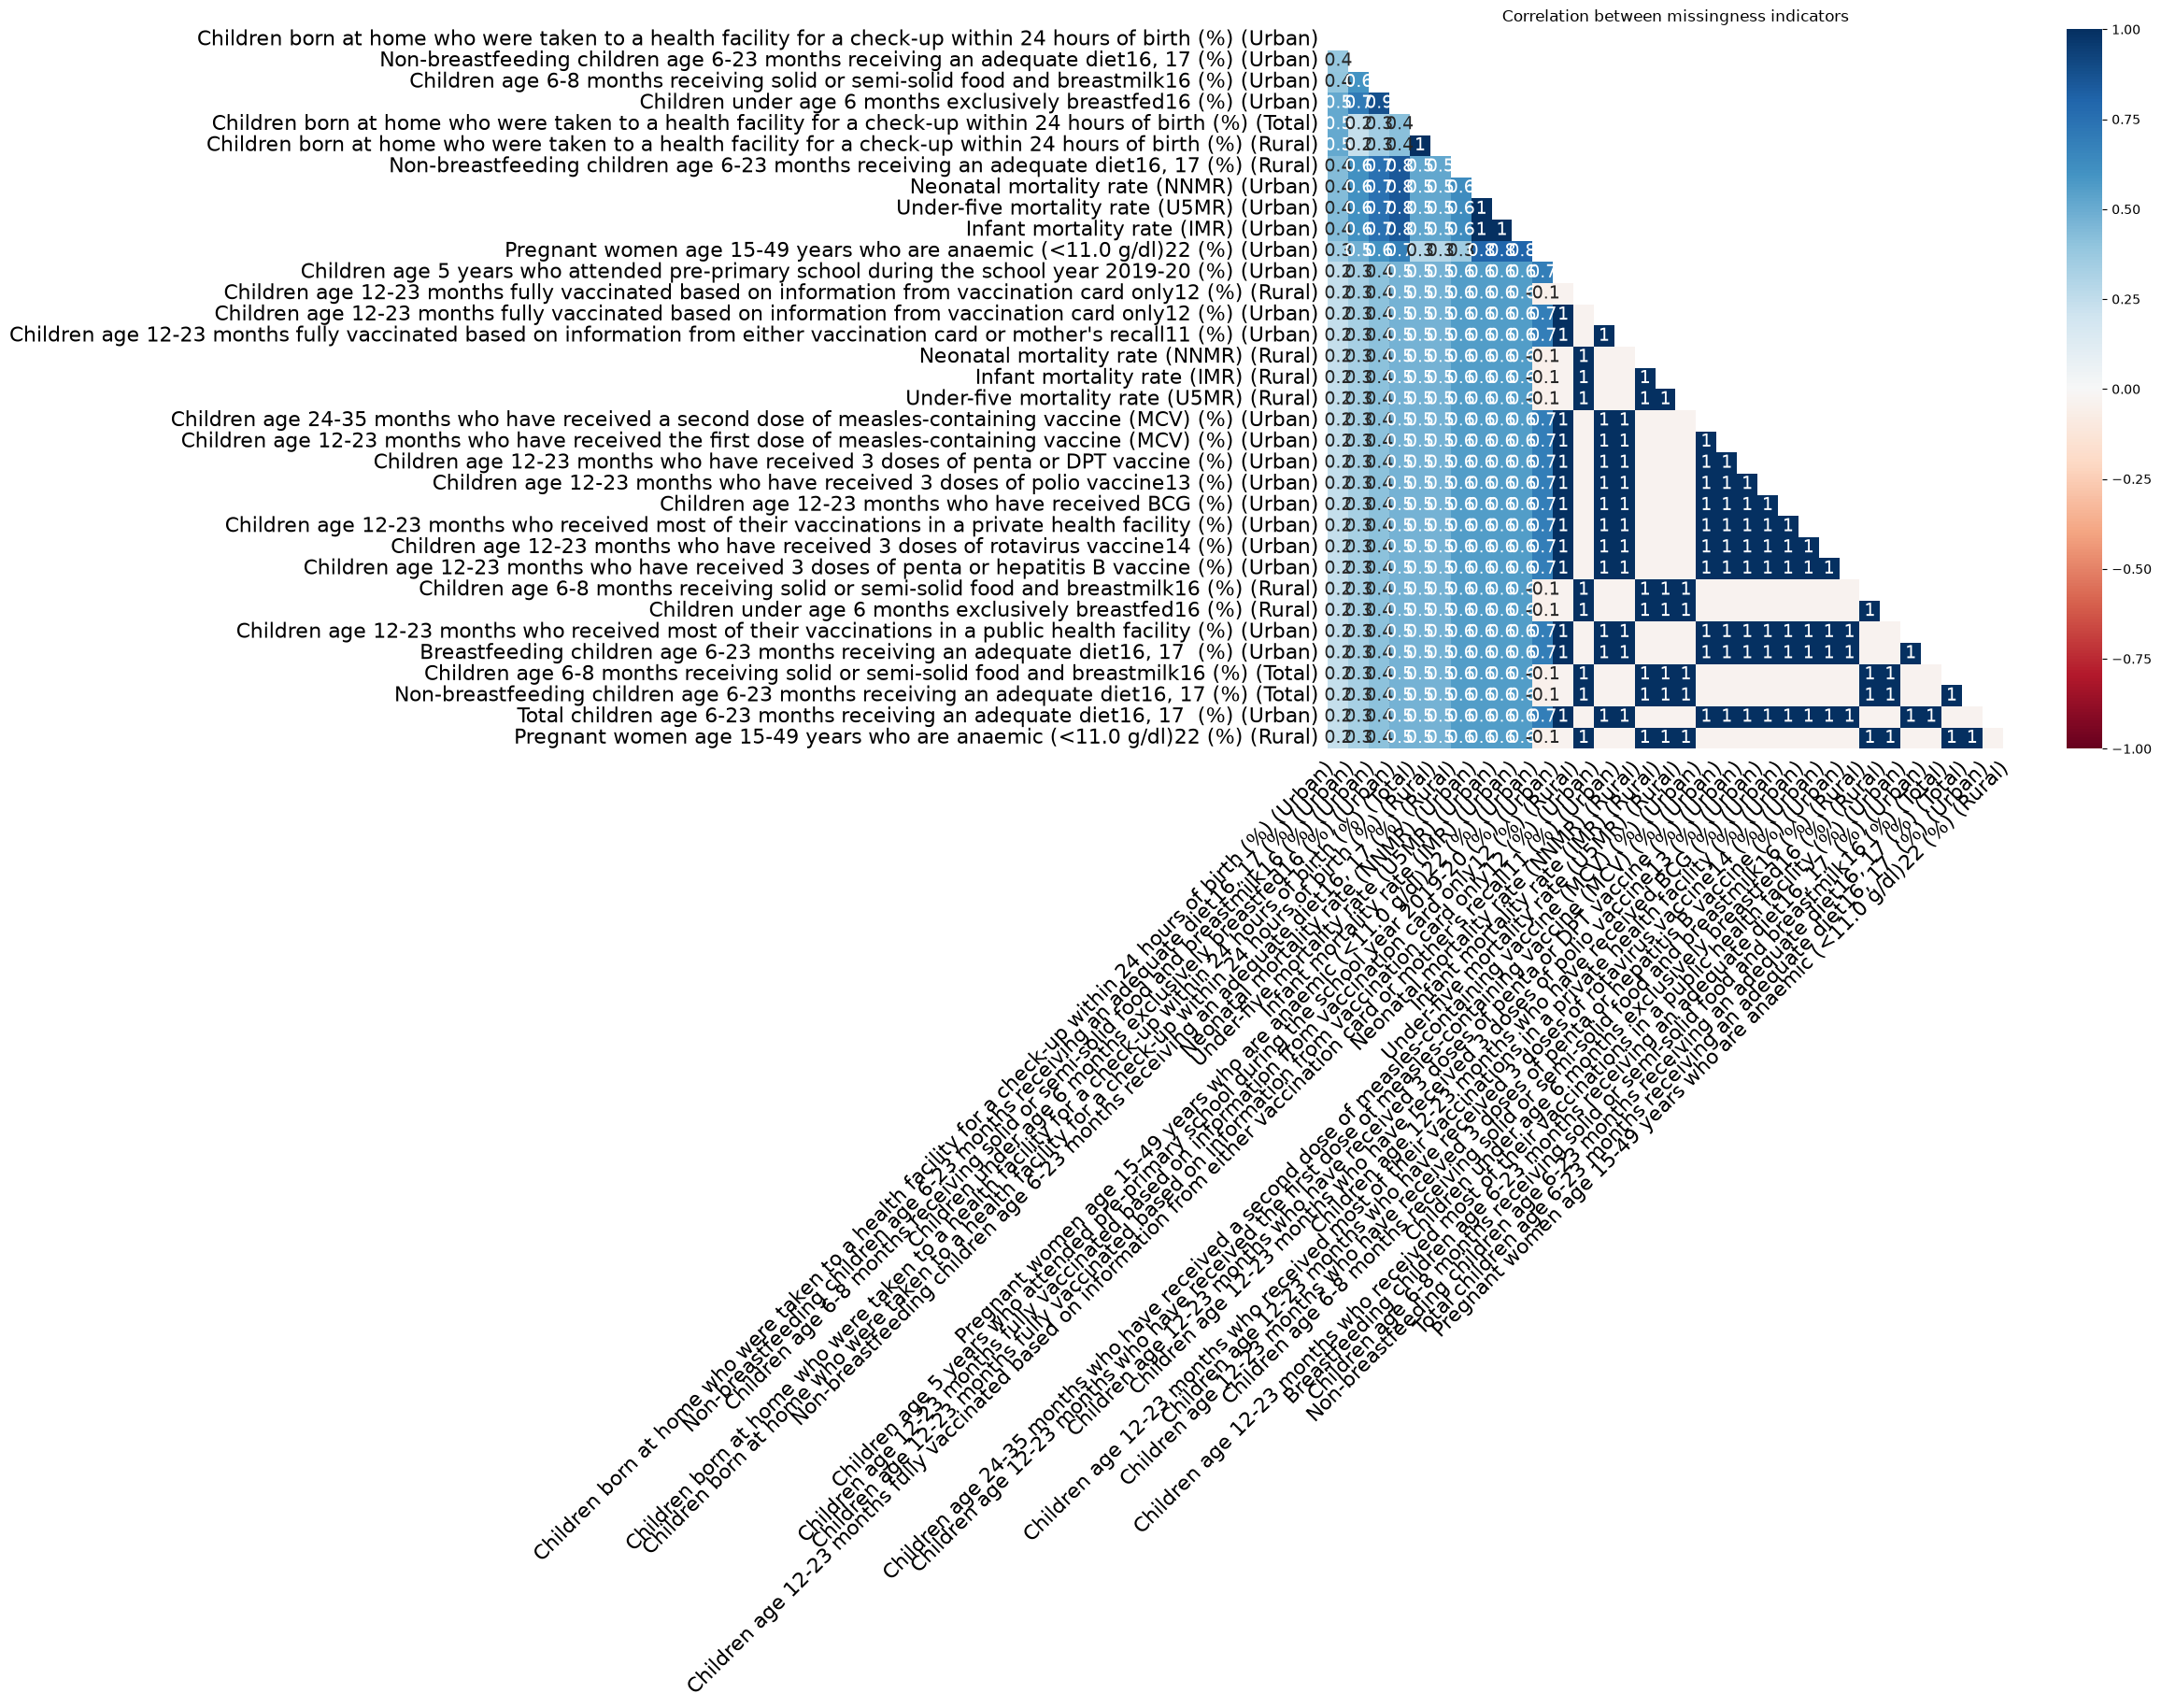

In [52]:
fig, ax = plt.subplots(figsize=(12, 10))
msno.heatmap(df[missing_cols], ax=ax, cmap="RdBu")
ax.set_title("Correlation between missingness indicators")
plt.tight_layout()
plt.show()


Many Urban columns are missing together for the same small states, which makes sense
since a state with little or no urban population has nothing to report for that split.

### Little's MCAR test (global)

Tests whether missingness overall is unrelated to any observed value.

In [53]:
little_p = MCARTest(method="little").little_mcar_test(df[numeric_cols])
print(f"Little's MCAR test p-value: {little_p:.4f}")

alpha = 0.05
if little_p > alpha:
    print(f"p = {little_p:.3f} > {alpha}, fail to reject H0: consistent with MCAR.")
else:
    print(f"p = {little_p:.3f} <= {alpha}, reject H0: not completely random overall.")


Little's MCAR test p-value: 1.0000
p = 1.000 > 0.05, fail to reject H0: consistent with MCAR.


With about 160 numeric columns and only 29 rows, there are far more parameters than data
points, so this test is close to uninformative here.

## Imputation

We didn't use median or mean imputation, because each row is one state's profile for one
year, so pulling a missing value toward an across state typical figure would erase the state
level differences this project is studying.

Instead, for each column with missing values, we find the other numeric columns it correlates
with most strongly, then run `KNNImputer` restricted to that small feature set. This fills a
gap using the states most similar to it on the related indicators, which fits the Urban, Rural
and Total structure well since each indicator's three columns are themselves strongly
correlated with each other.

### Correlated features per column

In [54]:
def top_correlated_features(data, numeric_cols, target, n_features=6):
    corr_matrix = data[numeric_cols].corr()
    corrs = corr_matrix[target].drop(index=target).abs().sort_values(ascending=False)
    return corrs.head(n_features)

N_FEATURES = 6
feature_summary_rows = []
for col in missing_cols:
    top = top_correlated_features(df, numeric_cols, col, n_features=N_FEATURES)
    feature_summary_rows.append({
        "missing_column": col,
        "top_1": f"{top.index[0]} ({top.iloc[0]:.2f})",
        "top_2": f"{top.index[1]} ({top.iloc[1]:.2f})",
        "top_3": f"{top.index[2]} ({top.iloc[2]:.2f})",
    })

feature_summary = pd.DataFrame(feature_summary_rows).set_index("missing_column")
feature_summary.head(15)


,top_1,top_2,top_3
missing_column,,,
Children born at home who were taken to a health facility for a check-up within 24 hours of birth (%) (Urban),Children age 12-23 months who received most of...,Neonatal mortality rate (NNMR) (Urban) (0.48),Children age 24-35 months who have received a ...
"Non-breastfeeding children age 6-23 months receiving an adequate diet16, 17 (%) (Urban)",Total children age 6-23 months receiving an ad...,Non-breastfeeding children age 6-23 months rec...,Children under age 3 years breastfed within on...
Children age 6-8 months receiving solid or semi-solid food and breastmilk16 (%) (Urban),Children age 6-8 months receiving solid or sem...,Children age 6-8 months receiving solid or sem...,Children under age 3 years breastfed within on...
Children under age 6 months exclusively breastfed16 (%) (Urban),Children under age 6 months exclusively breast...,Children age 12-23 months who received most of...,Children under age 6 months exclusively breast...
Children born at home who were taken to a health facility for a check-up within 24 hours of birth (%) (Total),Children born at home who were taken to a heal...,Children age 9-59 months who received a vitami...,Children age 9-59 months who received a vitami...
Children born at home who were taken to a health facility for a check-up within 24 hours of birth (%) (Rural),Children born at home who were taken to a heal...,Children age 9-59 months who received a vitami...,Children age 9-59 months who received a vitami...
"Non-breastfeeding children age 6-23 months receiving an adequate diet16, 17 (%) (Rural)",Non-breastfeeding children age 6-23 months rec...,Total children age 6-23 months receiving an ad...,Total children age 6-23 months receiving an ad...
Neonatal mortality rate (NNMR) (Urban),Infant mortality rate (IMR) (Urban) (0.93),Under-five mortality rate (U5MR) (Urban) (0.90),Neonatal mortality rate (NNMR) (Total) (0.85)
Under-five mortality rate (U5MR) (Urban),Infant mortality rate (IMR) (Urban) (0.97),Neonatal mortality rate (NNMR) (Urban) (0.90),Under-five mortality rate (U5MR) (Total) (0.85)


### Correlation guided KNN imputation

In [55]:
def correlated_knn_impute(data, missing_cols, numeric_cols, n_features=6, n_neighbors=5):
    data = data.copy()
    ordered_cols = data[missing_cols].isna().sum().sort_values(ascending=True).index.tolist()
    for target in ordered_cols:
        top_feats = top_correlated_features(data, numeric_cols, target, n_features=n_features).index.tolist()
        use_cols = [target] + top_feats

        scaler = StandardScaler()
        scaled = scaler.fit_transform(data[use_cols])

        imputer = KNNImputer(n_neighbors=n_neighbors)
        filled_scaled = imputer.fit_transform(scaled)
        filled = scaler.inverse_transform(filled_scaled)

        data[target] = filled[:, 0]
    return data

df_clean = correlated_knn_impute(df, missing_cols, numeric_cols, n_features=N_FEATURES, n_neighbors=5)
print("Remaining missing values:", df_clean[numeric_cols].isna().sum().sum())


Remaining missing values: 0


### Before and after check

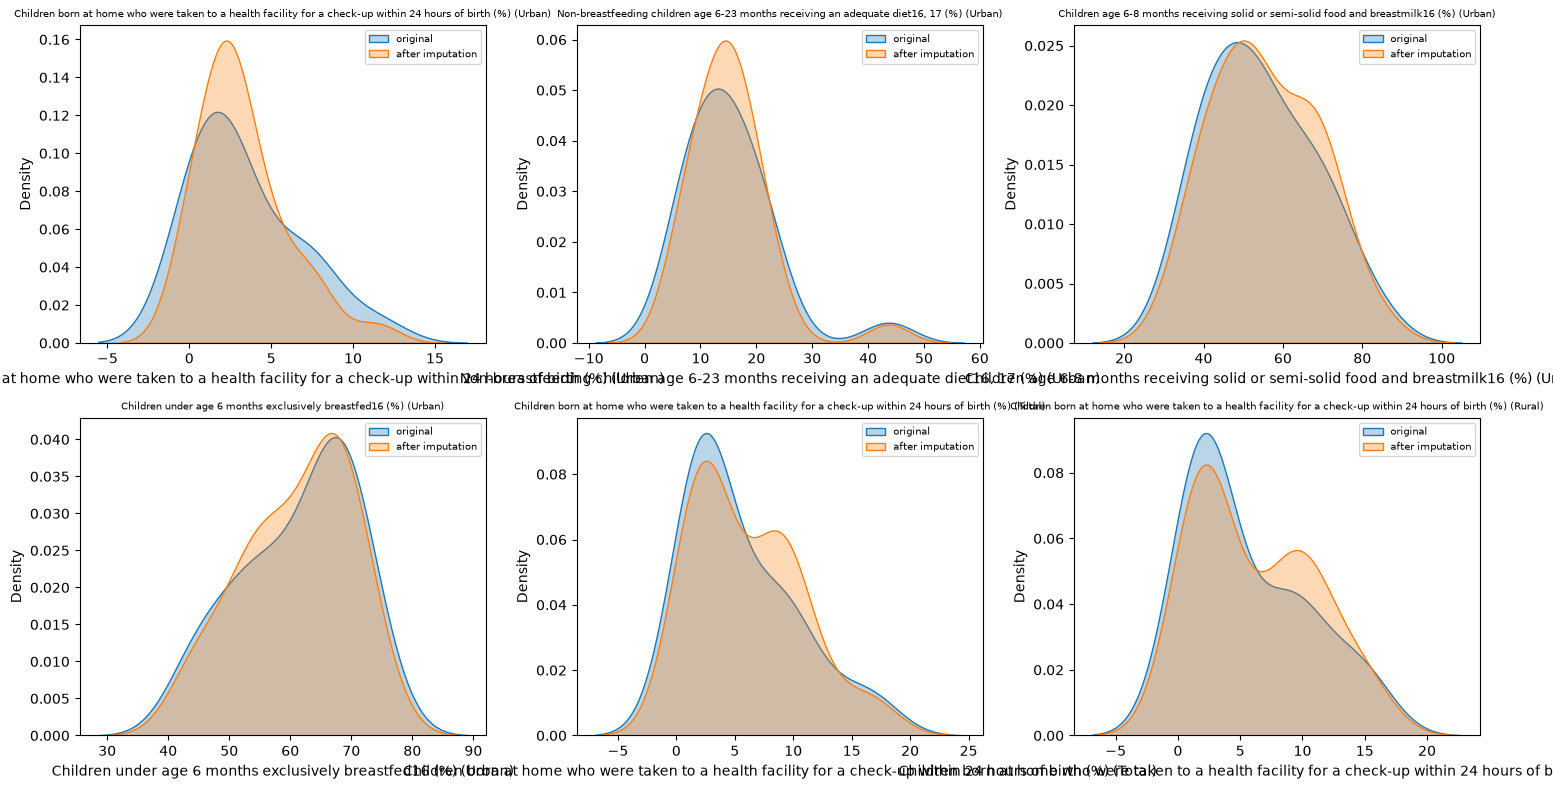

In [56]:
check_cols = missing_cols[:6]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.flat, check_cols):
    sns.kdeplot(df[c].dropna(), ax=ax, label="original", fill=True, alpha=0.3)
    sns.kdeplot(df_clean[c], ax=ax, label="after imputation", fill=True, alpha=0.3)
    ax.set_title(c, fontsize=7)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()


In [57]:
missing_after = df_clean.isna().sum()
assert missing_after.sum() == 0, "Missing values remain after imputation!"
print("All missing values resolved. Final shape:", df_clean.shape)
df_clean.head()


All missing values resolved. Final shape: (29, 167)


,State,Population (Total),Accounts,Budget Estimates,Revised Estimates,Population below age 15 years (%) (Urban),Population below age 15 years (%) (Rural),Population below age 15 years (%) (Total),"Sex ratio of the total population (females per 1,000 males) (Urban)","Sex ratio of the total population (females per 1,000 males) (Rural)",...,Women whose Body Mass Index (BMI) is below normal (BMI <18.5 kg/m2) (%) (Total),Women who are literate (%) (Urban),Women who are literate (%) (Rural),Women who are literate (%) (Total),Women with 10 or more years of schooling (%) (Urban),Women with 10 or more years of schooling (%) (Rural),Women with 10 or more years of schooling (%) (Total),Per_Capita_Health_Exp_Accounts,Per_Capita_Health_Exp_BE,Per_Capita_Health_Exp_RE
0,Andhra Pradesh,52504000.0,525929.6,605549.45,526323.02,21.3,22.6,22.2,1024,1055,...,14.8,79.0,63.8,68.6,51.2,34.3,39.6,1001.694347,1153.339650,1002.443661
1,Arunachal Pradesh,1519000.0,92615.0,131266.59,91612.20,26.2,27.2,27.1,989,998,...,5.7,82.9,69.0,71.3,55.4,36.2,39.4,6097.103357,8641.645161,6031.086241
2,Assam,34668000.0,451977.3,591193.62,633180.84,21.3,29.5,28.3,982,1017,...,17.6,87.5,75.4,77.2,49.0,26.2,29.6,1303.730530,1705.300623,1826.412946
3,Bihar,121302000.0,611797.7,638425.20,724500.80,31.6,37.2,36.4,982,1111,...,25.6,74.9,54.5,57.8,48.0,25.2,28.8,504.359120,526.310531,597.270284
4,Chhattisgarh,29109000.0,404904.7,403411.10,442702.30,23.2,26.0,25.4,1016,1014,...,23.1,83.4,69.1,72.5,52.4,32.1,36.9,1390.994881,1385.863822,1520.843382


## Save the cleaned dataset

In [58]:
OUT_PATH = "data/clean/budget_nfhs_combined_clean.csv"
df_clean.to_csv(OUT_PATH, index=False)
print(f"Saved cleaned data to {OUT_PATH}")


Saved cleaned data to data/clean/budget_nfhs_combined_clean.csv
